In [2]:
import sys
# from opentrons import protocol_api, execute, simulate
# from opentrons.types import Location, Point
import pandas as pd
import numpy as np
import random
import requests
import ast  # safer than eval
from pyDOE import lhs
import random
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed
from IPython.display import display, HTML
from color_mixing import GaussianProcess, BayesianOptimization

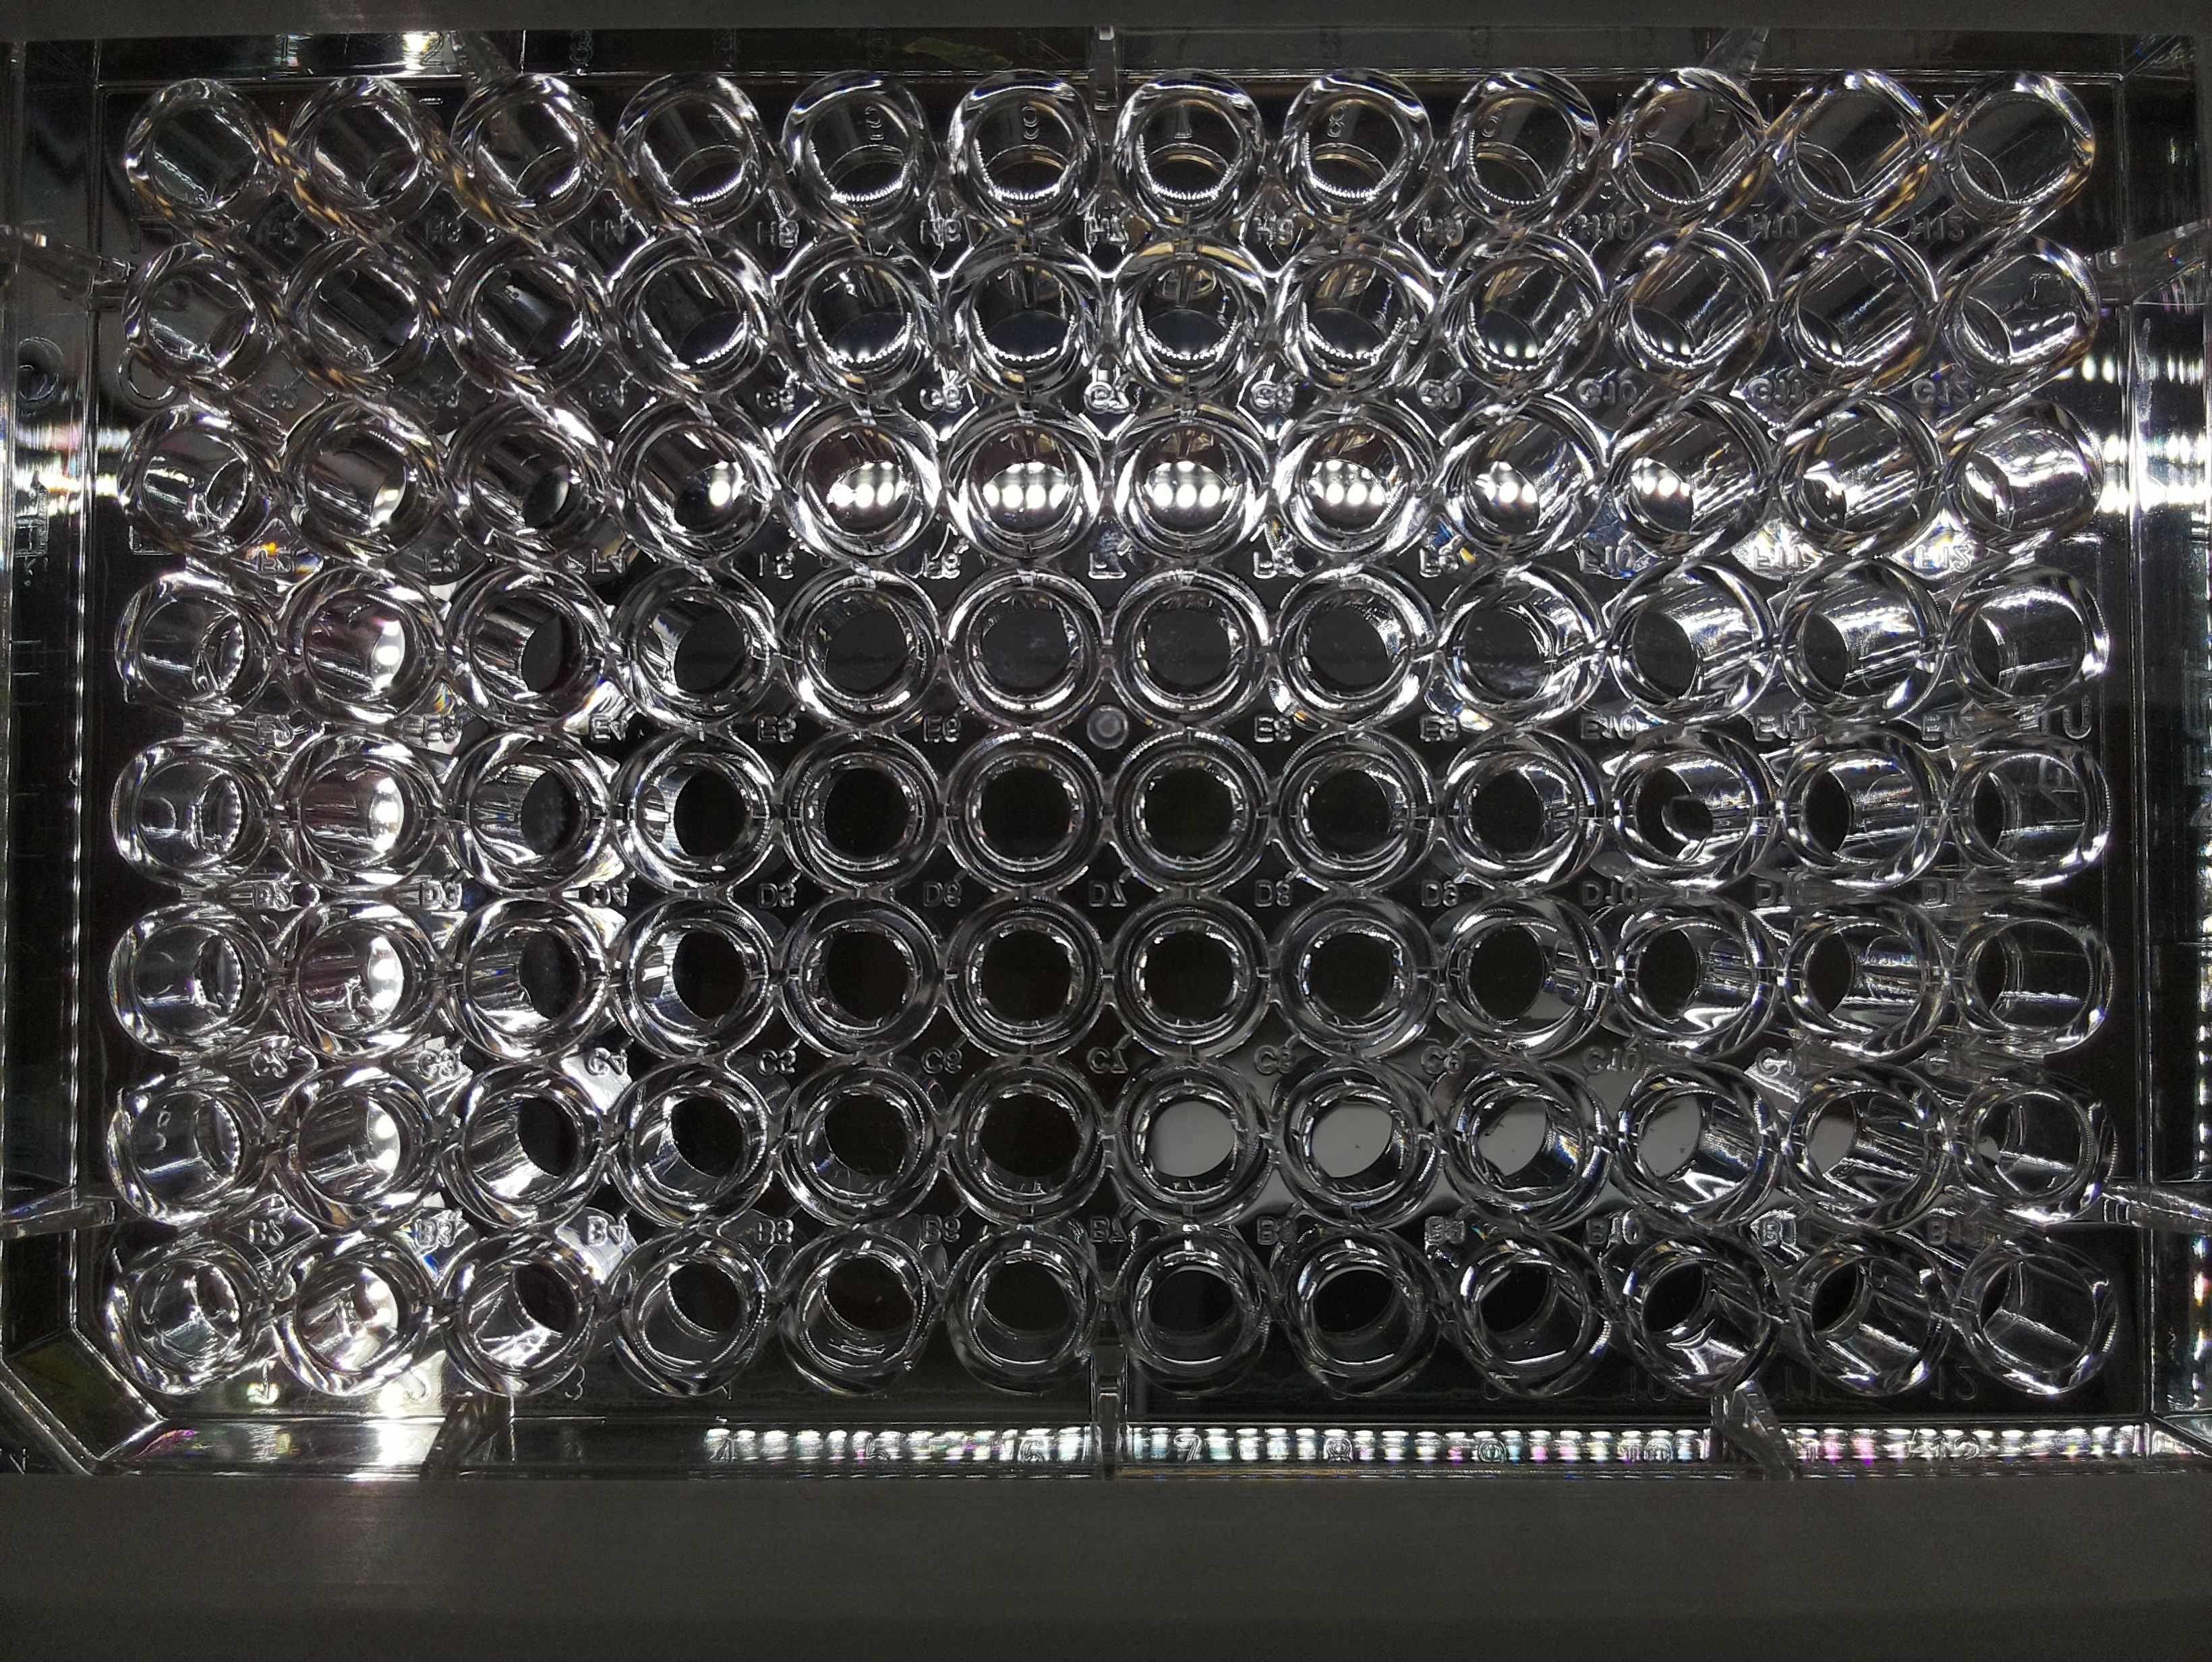

Image captured
Image saved .jpg
None


In [3]:
async def capture_photo(counter):
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(IPythonImage(data=img_data, format='jpg'))
            print("Image captured")

            with open(f"images/{counter}.jpg", "wb") as f:
                f.write(img_data)
            print("Image saved .jpg")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo(counter=0)
print(result)

In [4]:
counter = 'calibrate'
image_path = f"images/{counter}.jpg"
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

top_left = (250, 250)
bottom_right = (2800, 2000)
# Add sliders to control the top-left and bottom-right positions
top_left_x = IntSlider(value=top_left[0], min=0, max=image_rgb.shape[1], description="Top Left X")
top_left_y = IntSlider(value=top_left[1], min=0, max=image_rgb.shape[0], description="Top Left Y")
bottom_right_x = IntSlider(value=bottom_right[0], min=0, max=image_rgb.shape[1], description="Bottom Right X")
bottom_right_y = IntSlider(value=bottom_right[1], min=0, max=image_rgb.shape[0], description="Bottom Right Y")

@interact(top_left_x=top_left_x, top_left_y=top_left_y, bottom_right_x=bottom_right_x, bottom_right_y=bottom_right_y)
def update_grid(top_left_x, top_left_y, bottom_right_x, bottom_right_y):
    # Update coordinates for top-left and bottom-right grid points
    top_left = (top_left_x, top_left_y)
    bottom_right = (bottom_right_x, bottom_right_y)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))

            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]
            rgb_values.append([r, g, b])

    output_grid = image_rgb.copy()

    # Draw circles
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()


error: OpenCV(4.11.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\bilateral_filter.dispatch.cpp:409: error: (-215:Assertion failed) !_src.empty() in function 'cv::bilateralFilter'


In [ ]:
def image_rgb_extraction(image_path):
    # parameters for bilateral filtering
    diameter = 5
    sigmaColor = 75
    sigmaSpace = 75

    image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
    image_rgb = cv2.imread(image_path)

    rows = 8
    cols = 12

    # define coordinates for top-left and bottom-right grid points
    top_left = (265, 278)
    bottom_right = (2989, 2006)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    new_rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))
            
            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]  
            new_rgb_values.append([r, g, b]) 

    output_grid = image_rgb.copy()

    # draw circle
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()

    return new_rgb_values

In [ ]:
rgb_values = image_rgb_extraction(f"images/{counter}.jpg")
fig, ax = plt.subplots(figsize=(6, 4))
# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print('1st well:', rgb_values[84])
print('2nd well:', rgb_values[72])

ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()


In [ ]:
from pyDOE import lhs

# Number of samples
num_samples = 96

np.random.seed(0)  # Set seed for reproducibility
# Generate 5D Latin Hypercube Sampling
lhs_samples = lhs(4, samples=num_samples)

# Convert to volumes
lhs_samples_volumes = lhs_samples / lhs_samples.sum(axis=1, keepdims=True)* 100

# Convert lhs_samples_volumes to a DataFrame
lhs_df = pd.DataFrame(lhs_samples_volumes, columns=["volC", "volM", "volY", "volK"]).round(1)
lhs_df

In [ ]:
data_test = 'opentron_shared/data_test.csv'

# Increments of a 96 well plate
cell = [f"{chr(col)}{row}" for col in range(ord('A'), ord('H') + 1) for row in range(1, 13)]
# Generate IDs and wells for the new samples
lhs_df["id"] = range(0 ,len(lhs_df))
lhs_df["well"] = cell#[counter-1::12][:len(lhs_df)]
lhs_df = lhs_df[["id", "well", "volC", "volM", "volY", "volK"]]
lhs_df.to_csv(data_test, index=False)